# Avance Sem 5 · 

**Tesis:** *Generalización de políticas de aprendizaje por refuerzo ante diferentes niveles de fidelidad de simulación*
**Alumno:** Brayan Bruce Pérez Escobar · **Curso:** Proyecto de Investigación 2 · **Rama:** `sprint2-reorganizacion`


## 1. Preparación

Se cargan el entorno, las políticas de referencia y las funciones de evaluación del paquete `nanoswarm` (en `src/`). Toda la lógica vive en el paquete; el notebook solo la llama y muestra resultados, así el mismo código sirve para los scripts.

In [1]:
import dataclasses
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nanoswarm.baselines import make_policy
from nanoswarm.envs import VascularEnv
from nanoswarm.envs.dynamics import ACTIVE, AT_OTHER, AT_TARGET
from nanoswarm.envs.observation import OBS_NAMES
from nanoswarm.envs.reward import RewardWeights
from nanoswarm.evaluation import (ROOT, UNIT_WEIGHTS, bootstrap_ci, episode_seeds, evaluate, make_env,
                                  reward_alignment, reweight, run_and_log, summarize)
from nanoswarm.utils.rollout import run_episode, run_metadata
from nanoswarm.variants import VARIANTS

T_START = time.time()
pd.set_option("display.precision", 3)
print(json.dumps(run_metadata(), indent=2, ensure_ascii=False))

{
  "fecha": "2026-10-16T18:35:59",
  "git_commit": "b8fc348 (con cambios sin commit)",
  "python": "3.12.7",
  "plataforma": "Windows-11-10.0.26200-SP0",
  "numpy": "2.5.3",
  "gymnasium": "1.4.0",
  "pandas": "3.0.6"
}


In [2]:
# Estilo de los gráficos 
COLORS = {"zero": "#2a78d6", "random": "#eb6834", "heur_perp": "#1baf7a", "heur_branch": "#eda100"}
LABELS = {"zero": "Sin fuerza", "random": "Aleatoria",
          "heur_perp": "Heurística perpendicular", "heur_branch": "Heurística rama"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
STATUS_COLORS = {ACTIVE: "#9a9993", AT_TARGET: "#2a78d6", AT_OTHER: "#eb6834"}
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "figure.dpi": 110,
})
POLICY_ORDER = ["zero", "random", "heur_perp", "heur_branch"]


def eta_table(df):
    # η media por política (filas) y nivel (columnas)
    t = df.pivot_table(index="policy", columns="condition", values="eta", aggfunc="mean")
    return t.loc[[p for p in POLICY_ORDER if p in t.index]].rename(index=LABELS)


def separated(df, policy, a="R2", b="R3"):
    # ¿Los IC 95 % de η en los niveles a y b no se solapan?
    lo_a, hi_a = bootstrap_ci(df[(df.policy == policy) & (df.condition == a)].eta.to_numpy())
    lo_b, hi_b = bootstrap_ci(df[(df.policy == policy) & (df.condition == b)].eta.to_numpy())
    return hi_b < lo_a or hi_a < lo_b

### Partición de los datos: semillas de ajuste y de reporte

En RL no hay un dataset fijo que dividir en entrenamiento y prueba: **los datos los genera el simulador**. El equivalente es separar las **semillas**:

- **Ajuste** (5000–5019): se usan para **tomar decisiones**, como elegir los pesos de la recompensa o la magnitud máxima de la fuerza de control.
- **Reporte** (9000–9029): **nunca** se usan para decidir. Solo producen los resultados finales.

Así se evita la fuga de información: los números reportados no se usaron para ajustar nada. Es la regla de la clase: "divide primero, transforma después".

In [ ]:
ajuste, reporte = episode_seeds("ajuste"), episode_seeds("reporte")
# La política aleatoria usa su propio generador con semilla + 10 000
azar_ajuste, azar_reporte = {s + 10_000 for s in ajuste}, {s + 10_000 for s in reporte}
assert not set(ajuste) & set(reporte), "las particiones se solapan"
assert not azar_ajuste & azar_reporte
print(f"Ajuste : {len(ajuste)} semillas ({ajuste[0]}–{ajuste[-1]})")
print(f"Reporte: {len(reporte)} semillas ({reporte[0]}–{reporte[-1]})")
print("Sin solapamiento entre particiones ✓")

Ajuste : 20 semillas (5000–5019)
Reporte: 30 semillas (9000–9029)
Sin solapamiento entre particiones ✓


## 2. El simulador en una imagen

Un episodio con la **heurística rama** (empuja siempre hacia el brazo objetivo) en **R2** (corriente constante). Gris: bolitas aún en el vaso; azul: entregadas al objetivo; naranja: perdidas en el otro brazo.

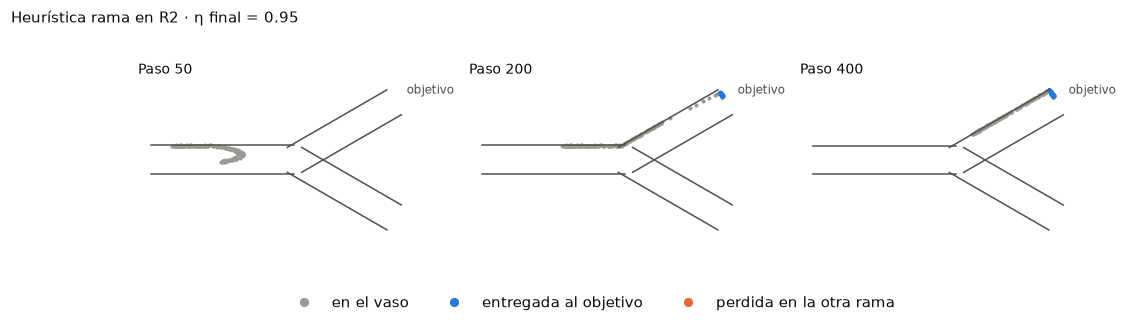

In [ ]:
def draw_geometry(ax, geom):
    for k in range(3):
        o, t, n, L = geom.origins[k], geom.tangents[k], geom.normals[k], geom.lengths[k]
        for side in (-1, 1):
            a = o + side * geom.half_width * n
            b = a + L * t
            ax.plot([a[0], b[0]], [a[1], b[1]], color=MUTED, linewidth=1)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def draw_swarm(ax, geom, pos, status, title):
    draw_geometry(ax, geom)
    for st, color in STATUS_COLORS.items():
        m = status == st
        ax.scatter(pos[m, 0], pos[m, 1], s=7, color=color, linewidths=0)
    ax.text(8.9, 2.3, "objetivo", color=MUTED, fontsize=8)
    ax.set_title(title, loc="left", fontsize=9)


def swarm_legend(fig):
    handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, markersize=5) for c in STATUS_COLORS.values()]
    fig.legend(handles, ["en el vaso", "entregada al objetivo", "perdida en la otra rama"],
               loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))


env = make_env(VARIANTS["baseline"], "R2")
summary, rec = run_episode(env, make_policy("heur_branch", env), seed=reporte[0], record_every=50)
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, k in zip(axes, [0, 3, 7]):
    pos, status = rec["frames"][k]
    draw_swarm(ax, env.geom, pos, status, f"Paso {50 * (k + 1)}")
swarm_legend(fig)
fig.suptitle(f"Heurística rama en R2 · η final = {summary['eta']:.2f}", x=0.02, ha="left", fontsize=10)
plt.show()

## 3. Punto de partida: el baseline (entorno del Sprint 1)

Se evalúan las cuatro políticas de referencia en los cuatro niveles, con 30 episodios por celda y las semillas de **reporte**:

| Política | Qué hace | Para qué sirve |
|---|---|---|
| Sin fuerza | Fuerza de control apagada | Muestra lo que hace la corriente sola |
| Aleatoria | Empuja al azar | Control sin estrategia |
| Heurística perpendicular | Cerca de la bifurcación empuja de lado, hacia el brazo objetivo | Regla simple |
| Heurística rama | Empuja siempre en la dirección del brazo objetivo | Regla simple; referencia principal |

In [ ]:
df = {}
df["baseline"] = run_and_log(VARIANTS["baseline"])
print(f"Cómputo: {df['baseline'].attrs['elapsed']:.0f} s · log: logs/metrics_sprint2_baseline.txt")
eta_table(df["baseline"])

Cómputo: 79 s · log: logs/metrics_sprint2_baseline.txt


condition,R1,R2,R3,R4
policy,,,,
Sin fuerza,0.000,0.469,4.693e-01,0.462
Aleatoria,0.000,0.450,4.558e-01,0.464
Heurística perpendicular,0.000,0.000,1.667e-04,0.879
Heurística rama,0.976,0.952,9.510e-01,0.916


**Las tres fallas, con números:**

In [ ]:
b = df["baseline"]
r2 = b[b.condition == "R2"].groupby("policy")[["eta", "return"]].mean().loc[POLICY_ORDER].rename(index=LABELS)
print("Falla 1. En R2, ¿más puntos significa más bolitas entregadas?")
display(r2.rename(columns={"eta": "η", "return": "puntos (retorno)"}))
print(f"→ Correlación de Spearman puntos–η en R2: {reward_alignment(b)['R2']:.2f} (debería ser ≥ 0.9)\n")

perp = b[b.policy == "heur_perp"].groupby("condition").eta.mean()
print(f"Falla 2. Heurística perpendicular: η = {perp['R2']:.2f} en R2 frente a {perp['R4']:.2f} en R4 (bolitas pegadas a la pared)\n")

t = eta_table(b)
print("Falla 3. Diferencia de η entre R3 y R2, por política:")
print((t["R3"] - t["R2"]).abs().round(3).to_string())

Falla 1. En R2, ¿más puntos significa más bolitas entregadas?


,η,puntos (retorno)
policy,,
Sin fuerza,0.469,0.526
Aleatoria,0.450,0.300
Heurística perpendicular,0.000,0.533
Heurística rama,0.952,1.647


→ Correlación de Spearman puntos–η en R2: 0.72 (debería ser ≥ 0.9)

Falla 2. Heurística perpendicular: η = 0.00 en R2 frente a 0.88 en R4 (bolitas pegadas a la pared)

Falla 3. Diferencia de η entre R3 y R2, por política:
policy
Sin fuerza                  0.000
Aleatoria                   0.006
Heurística perpendicular    0.000
Heurística rama             0.001


- **Falla 1:** la heurística perpendicular entrega casi **0 bolitas** en R2 y recibe casi **los mismos puntos** que no hacer nada, que entrega la mitad. La recompensa no distingue lo bueno de lo malo.
- **Falla 2:** la misma regla pasa de casi 0 % en R2 a cerca de 88 % en R4. Sin temblor, las bolitas empujadas contra la pared se quedan donde la corriente es cero.
- **Falla 3:** R3 y R2 difieren en menos de 0.01 en todas las políticas.

## 4. Diseño experimental: una cosa a la vez

Las variantes son **acumulativas**: cada una parte de la anterior y cambia **una sola cosa**. Así, la diferencia entre dos variantes seguidas se atribuye a ese cambio (ablación gradual).

| Variante | Único cambio | Falla que ataca | Criterio de éxito (decidido antes de medir) |
|---|---|---|---|
| Baseline | Entorno v0.1 del Sprint 1 | — | — |
| **Var1** | Recompensa corregida | 1 | Spearman puntos–η ≥ 0.9 en R2 y R3; la heurística perpendicular recibe menos puntos que "sin fuerza" en R2 |
| **Var2** | + radio de partícula | 2 | La heurística perpendicular deja de quedar atascada en R2 |
| **Var3** | + pulso fuerte y lento | 3 | η en R3 distinta de R2 (IC 95 % sin solaparse) en ambas heurísticas |
| **Var4** | + $F_{\max}$ en régimen marginal (con el horizonte ajustado) | 3 | Igual que Var3, sin volver imposible R1. Esta variante se agregó después del resultado de Var3 (sección 7) |

**Métricas** (las de Proyecto.pdf):
- **Principal:** η.
- **Secundarias:** fracción perdida en la otra rama, tiempo de tránsito, esfuerzo de control (0 = sin fuerza, 1 = fuerza máxima todo el tiempo) y costo de cómputo.
- La eficiencia muestral y la estabilidad entre semillas de entrenamiento solo existen cuando hay aprendizaje; se miden desde el piloto con PPO.

In [ ]:
pd.DataFrame([{"variante": v.name, "cambio": v.change,
               "radio": v.physics.particle_radius, "amplitud pulso": v.physics.pulse_amplitude,
               "período pulso": v.physics.pulse_period, "F_max": v.physics.v_mag,
               "w_p": v.reward.progress, "w_m": v.reward.other, "w_u": v.reward.effort}
              for v in VARIANTS.values()]).set_index("variante")

,cambio,radio,amplitud pulso,período pulso,v_mag,w_p,w_m,w_u
variante,,,,,,,,
baseline,Entorno v0.1 (Sprint 1),0.00,0.5,4.0,0.3,1.0,1.0,5.000e-04
var1,Recompensa corregida,0.00,0.5,4.0,0.3,0.1,0.5,1.000e-04
var2,+ radio de partícula a = 0.05 W,0.05,0.5,4.0,0.3,0.1,0.5,1.000e-04
var3,"+ pulso fuerte y lento (A = 0.9, T = 20)",0.05,0.9,20.0,0.3,0.1,0.5,1.000e-04
var4,"+ imán en régimen marginal (v_mag = 0.2, horiz...",0.05,0.9,20.0,0.2,0.1,0.5,1.000e-04


## 5. Var1: corregir la recompensa

### 5.1 Qué es la recompensa y por qué fallaba

En cada paso el agente recibe puntos según cuatro términos:

$$r_t = \underbrace{w_p\,\Delta \bar{d}}_{\text{acercarse}} + \underbrace{w_e\,\Delta \eta_{\text{obj}}}_{\text{entregar al objetivo}} - \underbrace{w_m\,\Delta \eta_{\text{otras}}}_{\text{perder en la otra rama}} - \underbrace{w_u \lVert a_t \rVert^2}_{\text{esfuerzo de control}}$$

Los pesos $w$ dicen cuánto vale cada cosa. En el baseline, los tres primeros valen 1 y el esfuerzo 0.0005. Eso produce tres distorsiones:

1. **Premio por acercarse sin entregar** ($w_p = 1$): una regla que deja las bolitas atascadas cerca del objetivo cobra puntos sin entregar nada.
2. **Castigo por la otra rama tan grande como el premio** ($w_m = w_e$): "no hacer nada" (50 % y 50 %) suma casi cero, igual que no entregar ninguna.
3. **Fuerza demasiado cara** ($w_u = 0.0005$): aplicar la fuerza máxima durante todo el episodio cuesta 0.4 puntos, más que la diferencia de η entre dos buenas estrategias.

### 5.2 Cómo se eligieron los nuevos pesos (con semillas de ajuste)

- **$w_u$ se fija por una regla, no se ajusta:** la fuerza máxima durante los 800 pasos debe costar como mucho 0.08 puntos, frente a 1 punto por entregar todo el enjambre. Eso da $w_u = 0.0001$.
- **$w_p$ y $w_m$ se ajustan** con una rejilla pequeña de 3 × 3 valores. La clase pide como máximo dos hiperparámetros y rangos pequeños.
- **Regla de selección, fijada antes de mirar:** entre las combinaciones que cumplen los criterios, se elige la de **mayor correlación mínima** en R2–R4.

Como los pesos no cambian la física, se corre **una sola vez** con pesos unitarios y el retorno de cada combinación se recalcula sin volver a simular.

In [ ]:
df_tune = evaluate(VARIANTS["baseline"], "ajuste", reward=UNIT_WEIGHTS)
rows = []
for wp in [1.0, 0.5, 0.1]:
    for wm in [1.0, 0.5, 0.25]:
        w = RewardWeights(progress=wp, target=1.0, other=wm, effort=0.0001)
        ret = reweight(df_tune, w)
        rho = reward_alignment(df_tune, ret)
        m = df_tune.assign(ret=ret).groupby(["condition", "policy"]).ret.mean()
        rows.append({"w_p": wp, "w_m": wm, "ρ R2": rho["R2"], "ρ R3": rho["R3"], "ρ R4": rho["R4"],
                     "perp < sin fuerza (R2)": m["R2", "heur_perp"] < m["R2", "zero"]})
grid = pd.DataFrame(rows)
grid["cumple"] = (grid["ρ R2"] >= 0.9) & (grid["ρ R3"] >= 0.9) & grid["perp < sin fuerza (R2)"]
grid["ρ mínima"] = grid[["ρ R2", "ρ R3", "ρ R4"]].min(axis=1)
best = grid[grid.cumple].sort_values("ρ mínima", ascending=False).iloc[0]
print(f"Elegido con semillas de ajuste: w_p = {best.w_p}, w_m = {best.w_m}")
assert (best.w_p, best.w_m) == (VARIANTS["var1"].reward.progress, VARIANTS["var1"].reward.other)
grid

Elegido con semillas de ajuste: w_p = 0.1, w_m = 0.5


,w_p,w_m,ρ R2,ρ R3,ρ R4,perp < sin fuerza (R2),cumple,ρ mínima
0,1.0,1.00,0.589,0.586,0.996,False,False,0.586
1,1.0,0.50,0.960,0.952,0.995,True,True,0.952
2,1.0,0.25,0.979,0.977,0.994,True,True,0.977
3,0.5,1.00,0.733,0.684,0.996,False,False,0.684
4,0.5,0.50,0.980,0.974,0.994,True,True,0.974
5,0.5,0.25,0.985,0.984,0.993,True,True,0.984
6,0.1,1.00,0.796,0.792,0.995,True,False,0.792
7,0.1,0.50,0.987,0.985,0.992,True,True,0.985
8,0.1,0.25,0.986,0.983,0.988,True,True,0.983


*(R1 no entra en el criterio: ahí tres políticas entregan exactamente 0 y empatan, lo que limita cualquier correlación.)*

### 5.3 Resultado con semillas de reporte

In [ ]:
df["var1"] = run_and_log(VARIANTS["var1"])
# Control de calidad: Var1 solo cambia la recompensa, así que η debe ser idéntica al baseline
assert np.allclose(df["var1"].eta.to_numpy(), df["baseline"].eta.to_numpy())
print("η idéntica al baseline en los 480 episodios ✓ (solo cambió la recompensa)\n")

align = pd.DataFrame({v: reward_alignment(df[v]) for v in ["baseline", "var1"]}).T
display(align.style.format("{:.3f}").set_caption("Spearman puntos–η por nivel"))
pts = pd.DataFrame({v: df[v][df[v].condition == "R2"].groupby("policy")["return"].mean() for v in ["baseline", "var1"]})
pts["η (R2)"] = df["var1"][df["var1"].condition == "R2"].groupby("policy").eta.mean()
pts.loc[POLICY_ORDER].rename(index=LABELS).style.format("{:.3f}").set_caption("Puntos medios en R2")

η idéntica al baseline en los 480 episodios ✓ (solo cambió la recompensa)



,R1,R2,R3,R4
baseline,0.812,0.717,0.545,0.927
var1,0.812,0.975,0.970,0.995


,baseline,var1,η (R2)
policy,,,
Sin fuerza,0.526,0.283,0.469
Aleatoria,0.300,0.220,0.450
Heurística perpendicular,0.533,0.041,0.000
Heurística rama,1.647,0.992,0.952


## 6. Var2: darle tamaño a las partículas

**El problema:** en un tubo, el líquido va más rápido en el centro y está **quieto junto a la pared**. Una partícula simulada como un punto puede quedar exactamente en la pared, donde no la arrastra nada, y quedarse congelada para siempre. Una partícula real tiene tamaño: su centro nunca toca la pared, así que siempre recibe algo de corriente.

**El cambio:** el centro de cada partícula rebota a una distancia $a$ de la pared, con $a = 0.05$ del ancho del vaso. Corresponde a agregados de nanopartículas de algunos micrómetros en vasos de decenas de micrómetros. El radio se aplica en **los cuatro niveles**, porque es una propiedad de la partícula y no del nivel de realismo.

condition,R1,R2,R3,R4
var1,0.000,0.000,0.000,0.879
var2,0.000,0.950,0.951,0.899


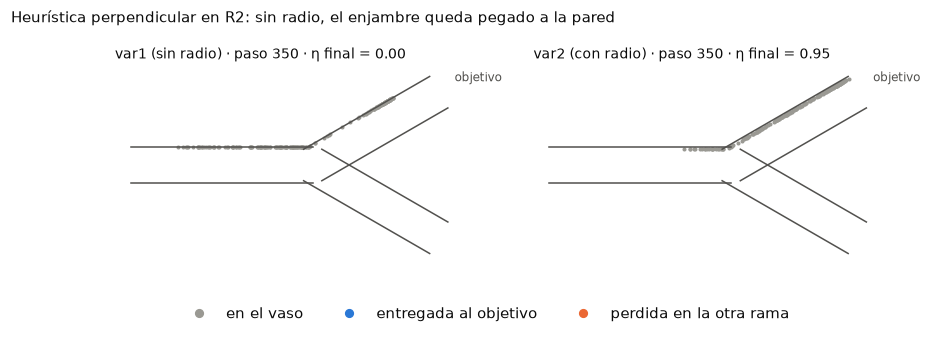

In [ ]:
df["var2"] = run_and_log(VARIANTS["var2"])
cmp = pd.DataFrame({v: df[v][df[v].policy == "heur_perp"].groupby("condition").eta.mean() for v in ["var1", "var2"]}).T
display(cmp.style.format("{:.3f}").set_caption("Heurística perpendicular: η por nivel, antes y después del radio"))

fig, axes = plt.subplots(1, 2, figsize=(9, 2.9))
for ax, v in zip(axes, ["var1", "var2"]):
    env = make_env(VARIANTS[v], "R2")
    s, rec = run_episode(env, make_policy("heur_perp", env), seed=reporte[0], record_every=50)
    pos, status = rec["frames"][6]
    draw_swarm(ax, env.geom, pos, status, f"{v} ({'sin radio' if v == 'var1' else 'con radio'}) · paso 350 · η final = {s['eta']:.2f}")
swarm_legend(fig)
fig.suptitle("Heurística perpendicular en R2: sin radio, el enjambre queda pegado a la pared", x=0.02, ha="left", fontsize=10)
plt.show()

## 7. Var3: un latido más fuerte y más lento

**Por qué R3 salía igual que R2:** en los dos niveles la corriente recorre **los mismos caminos**; en R3 solo cambia la rapidez. Una bolita arrastrada llega al mismo brazo, antes o después. Además, el latido era suave (±50 %) y rápido: el enjambre cruzaba la bifurcación durante unos 3 latidos y el efecto se promediaba.

**El cambio:** latido de ±90 %, de modo que la corriente casi se detiene en cada pulso, y período de 20 en lugar de 4, para que dure aproximadamente lo mismo que el cruce del enjambre por la bifurcación.

In [ ]:
df["var3"] = run_and_log(VARIANTS["var3"])
display(eta_table(df["var3"]).style.format("{:.3f}").set_caption("Var3: η por política y nivel"))
for pol in ["heur_perp", "heur_branch"]:
    print(f"{LABELS[pol]}: ¿R3 distinto de R2 (IC 95 % sin solaparse)? {separated(df['var3'], pol)}")

condition,R1,R2,R3,R4
policy,,,,
Sin fuerza,0.000,0.469,0.469,0.472
Aleatoria,0.000,0.461,0.488,0.480
Heurística perpendicular,0.000,0.950,0.950,0.835
Heurística rama,0.980,0.955,0.954,0.871


Heurística perpendicular: ¿R3 distinto de R2 (IC 95 % sin solaparse)? False
Heurística rama: ¿R3 distinto de R2 (IC 95 % sin solaparse)? False


**Resultado: el criterio no se cumple.** Las dos heurísticas siguen entregando alrededor del 95 % en R2 y en R3.

**Por qué:** con $F_{\max} = 0.3$ (relativa a la velocidad del flujo), la fuerza de control es tan grande que domina en todo momento del latido, y una regla fija ya resuelve la tarea casi perfectamente. Si la tarea es trivial en R2 y en R3, ningún cambio del flujo la vuelve distinta. Esto tiene otra consecuencia: **no le deja margen a un agente que aprende**, porque una regla fija ya está en el techo.

Esto es justamente una **iteración guiada por el EDA**: el resultado negativo indica el siguiente cambio.

## 8. Var4: fuerza máxima en régimen marginal

**La idea:** el latido importa cuando la fuerza de control **no domina siempre**. Si su magnitud máxima es algo menor, solo logra desviar a las partículas cuando la corriente está lenta, en el valle del pulso. Entonces **el momento en que se empuja importa**, y R3 se vuelve un problema realmente distinto de R2. Es justo lo que un agente que observa la fase del pulso podría aprender a aprovechar.

La fuerza sigue siendo **idealizada y constante**: $F_{\max}$ es un parámetro fijo del entorno, igual en todos los niveles, no un factor de estudio. Solo se fija su valor.

**Cómo se fija el valor, con semillas de ajuste:** se prueban 5 valores de $F_{\max}$ y se elige **el mayor con el que R3 se distingue de R2 en ambas heurísticas**. Es el más fuerte posible para cambiar lo mínimo respecto del diseño original.

**El horizonte acompaña a $F_{\max}$.** Sin corriente (R1), solo la fuerza de control mueve las partículas: con una fuerza máxima menor tardan más en cruzar el vaso. Si el episodio se sigue cortando a los 800 pasos, R1 se vuelve imposible. Por eso el límite de pasos crece en la misma proporción en que baja la fuerza, $800 \times 0.3 / F_{\max}$ (1200 pasos para $F_{\max} = 0.2$), y se conserva el mismo margen de tiempo que en el diseño original. No es un cambio aparte, sino la consecuencia directa de reducir $F_{\max}$.

In [ ]:
rows = []
for v in [0.10, 0.15, 0.20, 0.25, 0.30]:
    var = dataclasses.replace(VARIANTS["var3"], physics=dataclasses.replace(VARIANTS["var3"].physics, v_mag=v),
                              horizon=round(800 * 0.3 / v))
    d = evaluate(var, "ajuste", policies=["heur_perp", "heur_branch"], conditions=["R2", "R3"])
    row = {"F_max": v}
    for pol in ["heur_perp", "heur_branch"]:
        e = d[d.policy == pol].groupby("condition").eta.mean()
        row[f"{LABELS[pol]} R2"], row[f"{LABELS[pol]} R3"] = e["R2"], e["R3"]
        row[f"separa ({pol})"] = separated(d, pol)
    rows.append(row)
sweep = pd.DataFrame(rows).set_index("F_max")
chosen = sweep[sweep["separa (heur_perp)"] & sweep["separa (heur_branch)"]].index.max()
print(f"Elegido con semillas de ajuste: F_max = {chosen}")
assert chosen == VARIANTS["var4"].physics.v_mag
sweep

Elegido con semillas de ajuste: v_mag = 0.2


,Heurística perpendicular R2,Heurística perpendicular R3,separa (heur_perp),Heurística rama R2,Heurística rama R3,separa (heur_branch)
v_mag,,,,,,
0.10,0.582,0.508,True,0.723,0.642,True
0.15,0.951,0.553,True,0.910,0.737,True
0.20,0.951,0.674,True,0.956,0.846,True
0.25,0.950,0.927,True,0.955,0.954,False
0.30,0.950,0.950,False,0.957,0.955,False


In [ ]:
df["var4"] = run_and_log(VARIANTS["var4"])
display(eta_table(df["var4"]).style.format("{:.3f}").set_caption("Var4: η por política y nivel (semillas de reporte)"))
for pol in ["heur_perp", "heur_branch"]:
    print(f"{LABELS[pol]}: ¿R3 distinto de R2? {separated(df['var4'], pol)} · ¿R4 distinto de R3? {separated(df['var4'], pol, 'R3', 'R4')}")

condition,R1,R2,R3,R4
policy,,,,
Sin fuerza,0.000,0.469,0.469,0.472
Aleatoria,0.000,0.463,0.482,0.472
Heurística perpendicular,0.000,0.950,0.667,0.711
Heurística rama,0.969,0.953,0.842,0.785


Heurística perpendicular: ¿R3 distinto de R2? True · ¿R4 distinto de R3? True
Heurística rama: ¿R3 distinto de R2? True · ¿R4 distinto de R3? True


## 9. Resultados comparables

### 9.1 Tabla estándar

Una fila por variante. **η** es de la heurística rama, la referencia principal. Las secundarias son promedios sobre los cuatro niveles, salvo que se indique otra cosa. El costo es el tiempo de cómputo de los 480 episodios de evaluación, en paralelo.

In [ ]:
ORDER = ["baseline", "var1", "var2", "var3", "var4"]
table = []
for v in ORDER:
    d = df[v]
    br = d[d.policy == "heur_branch"]
    e = br.groupby("condition").eta.mean()
    rho = reward_alignment(d)
    table.append({
        "variante": v, "cambio": VARIANTS[v].change,
        **{f"η {c}": e[c] for c in ["R1", "R2", "R3", "R4"]},
        "η perp. R2": d[(d.policy == "heur_perp") & (d.condition == "R2")].eta.mean(),
        "|η R3 − η R2|": abs(e["R3"] - e["R2"]),
        "ρ mín. R2–R3": min(rho["R2"], rho["R3"]),
        "pérdida": br.eta_other.mean(), "tránsito": br.transit.mean(), "esfuerzo": br.effort.mean(),
        "cómputo (s)": d.attrs["elapsed"],
    })
table = pd.DataFrame(table).set_index("variante")
table.style.format(precision=3).format("{:.0f}", subset=["cómputo (s)"])

,cambio,η R1,η R2,η R3,η R4,η perp. R2,|η R3 − η R2|,ρ mín. R2–R3,pérdida,tránsito,esfuerzo,cómputo (s)
variante,,,,,,,,,,,,
baseline,Entorno v0.1 (Sprint 1),0.976,0.952,0.951,0.916,0.000,0.001,0.545,0.009,20.166,1.000,79
var1,Recompensa corregida,0.976,0.952,0.951,0.916,0.000,0.001,0.970,0.009,20.166,1.000,85
var2,+ radio de partícula a = 0.05 W,0.980,0.955,0.956,0.918,0.950,0.001,0.860,0.009,16.973,1.000,79
var3,"+ pulso fuerte y lento (A = 0.9, T = 20)",0.980,0.955,0.954,0.871,0.950,0.001,0.860,0.020,15.608,1.000,69
var4,"+ imán en régimen marginal (v_mag = 0.2, horizonte 1200)",0.969,0.953,0.842,0.785,0.950,0.111,0.889,0.070,19.938,1.000,83


In [ ]:
def clear_inversions(d, tol=0.02):
    # Pares de políticas donde la que entrega claramente MENOS (> tol de η) recibe MÁS puntos
    m = d.groupby(["condition", "policy"])[["eta", "return"]].mean()
    count = 0
    for cond in m.index.get_level_values(0).unique():
        g = m.loc[cond]
        for a in g.index:
            for b in g.index:
                count += (g.loc[a, "eta"] > g.loc[b, "eta"] + tol) and (g.loc[a, "return"] < g.loc[b, "return"])
    return int(count)


# ¿Se cumplió cada criterio? (evaluado con semillas de reporte)
crit = pd.DataFrame({
    v: {
        "1. Recompensa alineada (ρ ≥ 0.9 en R2 y R3)": table.loc[v, "ρ mín. R2–R3"] >= 0.9,
        "1b. Sin premio por entregar menos (chequeo agregado, ver abajo)": clear_inversions(df[v]) == 0,
        "2. Sin atasco en la pared (η perp. R2 > 0.5)": table.loc[v, "η perp. R2"] > 0.5,
        "3. R3 distinto de R2 en ambas heurísticas": separated(df[v], "heur_perp") and separated(df[v], "heur_branch"),
    } for v in ORDER}).replace({True: "✓", False: "✗"})
display(crit)

# Log comparativo (lo pide la tarea: resultados en logs/metrics_*.txt)
with open(ROOT / "logs" / "metrics_sprint2_comparacion.txt", "w", encoding="utf-8") as f:
    f.write("# Sprint 2: comparación de variantes (semillas de reporte 9000–9029)\n\n")
    f.write("## Metadatos\n" + json.dumps(run_metadata(), indent=2, ensure_ascii=False) + "\n\n")
    f.write("## Tabla estándar (η y secundarias de la heurística rama)\n")
    f.write(table.to_string(float_format=lambda x: f"{x:.3f}") + "\n\n")
    f.write("## Criterios\n" + crit.to_string() + "\n")
print("Log: logs/metrics_sprint2_comparacion.txt")

,baseline,var1,var2,var3,var4
1. Recompensa alineada (ρ ≥ 0.9 en R2 y R3),✗,✓,✗,✗,✗
"1b. Sin premio por entregar menos (chequeo agregado, ver abajo)",✗,✓,✓,✓,✓
2. Sin atasco en la pared (η perp. R2 > 0.5),✗,✗,✓,✓,✓
3. R3 distinto de R2 en ambas heurísticas,✗,✗,✗,✗,✓


Log: logs/metrics_sprint2_comparacion.txt


**Sobre el criterio 1 a partir de Var2.** La correlación en R2 baja de 0.9 en cuanto se agrega el radio. La causa no es un engaño:

- Con el radio, **las dos heurísticas llegan al mismo techo en R2**: η ≈ 0.95, con diferencias de milésimas.
- La perpendicular aplica la fuerza ~10 % del tiempo y la rama el 100 %. Con η prácticamente igual, la recompensa le da **un poco más de puntos a la que gasta menos esfuerzo de control**, que es justo lo que pide el término de esfuerzo.
- Dentro de ese grupo empatado el orden por η es ruido, y eso baja la correlación global.

Para separar "empate en el techo" de "premio por no entregar", se **agregó después de ver el resultado** el chequeo 1b: ninguna política que entregue claramente menos (más de 0.02 de η) debe recibir más puntos. Se cumple en todas las variantes corregidas. Se declara como chequeo posterior, no como criterio original. La raíz del empate es que η tiene un techo en 0.95, porque el episodio termina cuando sale el 95 % del enjambre; queda como siguiente cambio candidato.

### 9.2 Gráfico clave: cómo cambia cada nivel con cada arreglo

Cada panel es una variante. En el eje horizontal están los cuatro niveles y en el vertical η, con su IC 95 %. Lo que se busca en el último panel es una **escalera**: que cada nivel más realista sea distinto, en vez de líneas planas o atascos en 0.

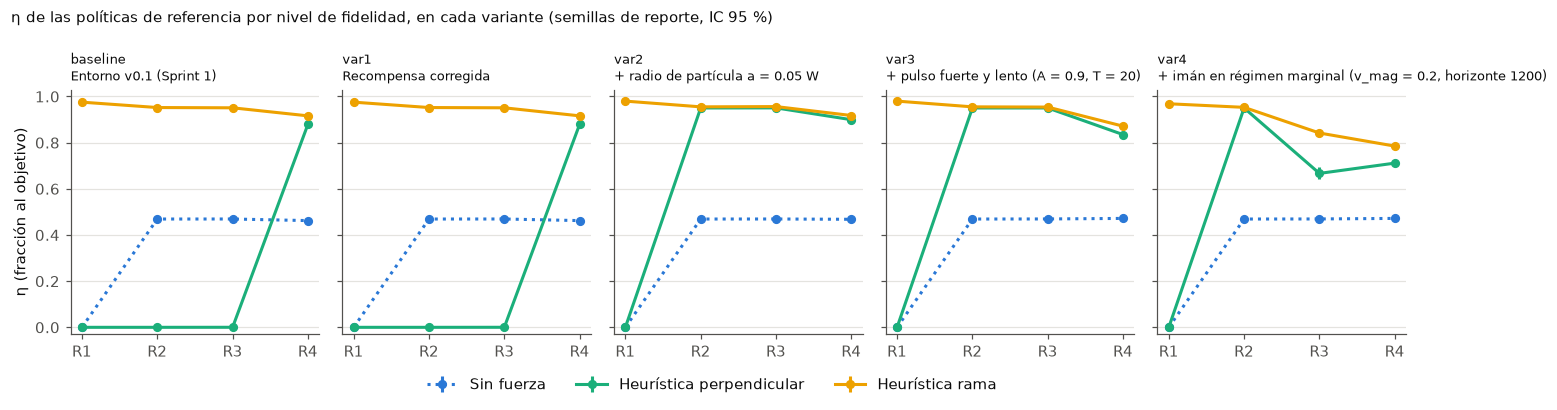

In [ ]:
fig, axes = plt.subplots(1, len(ORDER), figsize=(13, 3.4), sharey=True)
x = np.arange(4)
for ax, v in zip(axes, ORDER):
    s = summarize(df[v]).set_index(["policy", "condition"])
    for pol in ["zero", "heur_perp", "heur_branch"]:
        y = np.array([s.loc[(pol, c), "eta"] for c in ["R1", "R2", "R3", "R4"]])
        lo = np.array([s.loc[(pol, c), "eta_lo"] for c in ["R1", "R2", "R3", "R4"]])
        hi = np.array([s.loc[(pol, c), "eta_hi"] for c in ["R1", "R2", "R3", "R4"]])
        ls = ":" if pol == "zero" else "-"
        ax.errorbar(x, y, yerr=[y - lo, hi - y], color=COLORS[pol], linewidth=2, linestyle=ls,
                    marker="o", markersize=5, capsize=0, label=LABELS[pol])
    ax.set_xticks(x, ["R1", "R2", "R3", "R4"])
    ax.set_ylim(-0.03, 1.03)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{v}\n{VARIANTS[v].change}", loc="left", fontsize=8.5)
axes[0].set_ylabel("η (fracción al objetivo)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("η de las políticas de referencia por nivel de fidelidad, en cada variante (semillas de reporte, IC 95 %)",
             x=0.01, ha="left", fontsize=10)
fig.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "fig5_sprint2_variantes.png", bbox_inches="tight", dpi=130)
plt.show()

## 10. Features y pipeline

### 10.1 Las features: lo que observa el agente

En RL, las *features* son las variables de la **observación**: lo que el agente ve en cada paso para decidir. No es la lista de posiciones de las 200 bolitas, sino un **resumen de 11 números** construido con conocimiento del problema. Es feature engineering de dominio.

| # | Feature | Qué significa | Tipo de feature engineering (clase 04) |
|:---:|---|---|---|
| 1–2 | Centroide $(x, y)$ | Dónde está el centro del enjambre, **medido desde la bifurcación** | Creación (estadística del grupo) + transformación (origen en la bifurcación) |
| 3–4 | Dispersión $(x, y)$ | Qué tan esparcido está el enjambre | Creación (desviación estándar) |
| 5–7 | Fracciones entregadas, perdidas y en el vaso | Cómo va la tarea | Creación (ratios: conteo / N) |
| 8–9 | Fase del pulso $(\sin\varphi, \cos\varphi)$ | En qué momento del latido está la corriente | **Codificación cíclica**, igual que el ejemplo de los meses de la clase: el final de un latido queda cerca del inicio del siguiente |
| 10–11 | Acción anterior $(x, y)$ | Hacia dónde empujó en el paso previo | **Lag** $a_{t-1}$ |

**Cambios en este sprint:** no se agregó ni quitó ninguna feature. Los experimentos cambiaron el entorno, no la observación. La fase del pulso (8–9) gana importancia en Var3 y Var4: ahora el momento del latido decide si la fuerza de control domina. Su aporte real se medirá con PPO, con una ablación con y sin fase.

### 10.2 Transformación pendiente: normalización ajustada solo con entrenamiento

Las features tienen escalas muy distintas: el centroide llega a ±5 y las fracciones están entre 0 y 1. Las redes neuronales aprenden mejor con todo en una escala parecida, así que se **estandarizan**: $(x - \mu)/\sigma$.

La regla de la clase es que $\mu$ y $\sigma$ se calculan **solo con datos de entrenamiento** y después se aplican, congeladas, a validación y prueba. Se demuestra con el entorno final (Var4):

In [ ]:
def collect_obs(seeds, variant, policies=("random", "heur_branch")):
    obs = []
    for cond in ["R1", "R2", "R3", "R4"]:
        env = make_env(VARIANTS[variant], cond)
        for pol in policies:
            for s in seeds[:5]:
                _, rec = run_episode(env, make_policy(pol, env, seed=s + 10_000), s, record_every=10_000)
                obs.append(rec["obs"])
    return np.concatenate(obs)


class Standardizer:
    # (x − μ) / σ con μ y σ calculados SOLO en fit(); transform() no recalcula nada
    def fit(self, X):
        self.mu, self.sigma = X.mean(axis=0), X.std(axis=0) + 1e-8
        return self

    def transform(self, X):
        return (X - self.mu) / self.sigma


X_train = collect_obs(ajuste, "var4")    # "entrenamiento": semillas de ajuste
X_test = collect_obs(reporte, "var4")    # "prueba": semillas de reporte, nunca vistas en fit
scaler = Standardizer().fit(X_train)
Z_test = scaler.transform(X_test)
pd.DataFrame({"rango original (prueba)": [f"[{a:.2f}, {b:.2f}]" for a, b in zip(X_test.min(0), X_test.max(0))],
              "μ (de entrenamiento)": scaler.mu, "σ (de entrenamiento)": scaler.sigma,
              "media estandarizada (prueba)": Z_test.mean(0), "desv. estandarizada (prueba)": Z_test.std(0)},
             index=OBS_NAMES).style.format(precision=2)

,rango original (prueba),μ (de entrenamiento),σ (de entrenamiento),media estandarizada (prueba),desv. estandarizada (prueba)
centroid_x,"[-5.00, 3.24]",-1.24,2.91,0.02,1.01
centroid_y,"[-2.32, 2.39]",0.38,0.78,0.05,1.03
spread_x,"[0.00, 2.22]",0.48,0.55,-0.02,0.98
spread_y,"[0.00, 2.29]",0.43,0.46,-0.04,0.96
frac_target,"[0.00, 0.99]",0.15,0.22,0.00,0.99
frac_other,"[0.00, 0.69]",0.08,0.15,0.07,1.10
frac_active,"[0.01, 1.00]",0.77,0.33,-0.03,1.03
phase_sin,"[-1.00, 1.00]",0.11,0.69,0.00,1.00
phase_cos,"[-1.00, 1.00]",0.04,0.71,-0.01,1.00
prev_action_x,"[-1.00, 1.00]",0.39,0.59,-0.02,1.01


En prueba, las medias quedan cerca de 0 y las desviaciones cerca de 1 **sin haber usado esos datos para calcular μ y σ**. Eso confirma que la transformación generaliza sin fuga.

**Cómo será en el pipeline de PPO:** se usará `VecNormalize` de Stable-Baselines3, que actualiza μ y σ solo mientras la política entrena y los **congela** al evaluar (`training=False`). En la matriz de evaluación cruzada, cada política πRi usa **sus propias** μ y σ, las de su nivel de entrenamiento. Si se recalcularan con datos del nivel de prueba, la política recibiría información de ese nivel: sería fuga.

### 10.3 Lista de control de fuga de datos

| Riesgo de fuga | Cómo se evita | Comprobación |
|---|---|---|
| Decidir con los datos que se reportan | Todas las decisiones (pesos de la recompensa, $F_{\max}$) usan solo semillas de ajuste | Celdas de las secciones 5.2 y 8 (`evaluate(..., "ajuste")`) |
| Particiones que se solapan | Ajuste 5000–5019 y reporte 9000–9029, también para la política aleatoria | `assert` de la sección 1 |
| Normalización con datos de prueba | μ y σ se calculan solo en `fit()` con semillas de ajuste | Sección 10.2 |
| Fuga entre geometrías | No aplica todavía: hay una sola geometría | Cuando se agreguen (etapa 2), la de prueba se aísla desde el inicio |

## 11. Validación: ¿las decisiones se sostienen con datos nuevos? (holdout)

Las decisiones se tomaron con las semillas de **ajuste**. Si fueron buenas decisiones, y no casualidades de esas semillas, los resultados deben **repetirse con las semillas de reporte**, que nunca se usaron para decidir. Se compara el entorno final (Var4) en ambas particiones:

In [ ]:
df_v4_ajuste = evaluate(VARIANTS["var4"], "ajuste")
hold = pd.DataFrame({
    "ajuste (decidir)": df_v4_ajuste.groupby(["policy", "condition"]).eta.mean(),
    "reporte (holdout)": df["var4"].groupby(["policy", "condition"]).eta.mean(),
})
hold["diferencia"] = hold["reporte (holdout)"] - hold["ajuste (decidir)"]
print(f"Diferencia máxima entre particiones: {hold['diferencia'].abs().max():.3f}")
rho_a, rho_r = reward_alignment(df_v4_ajuste), reward_alignment(df["var4"])
print("Spearman puntos–η  ajuste:", {k: round(v, 3) for k, v in rho_a.items()})
print("Spearman puntos–η  reporte:", {k: round(v, 3) for k, v in rho_r.items()})
hold.unstack("condition").loc[POLICY_ORDER]["reporte (holdout)"].rename(index=LABELS)

Diferencia máxima entre particiones: 0.027
Spearman puntos–η  ajuste: {'R1': np.float64(0.812), 'R2': np.float64(0.882), 'R3': np.float64(0.996), 'R4': np.float64(0.997)}
Spearman puntos–η  reporte: {'R1': np.float64(0.813), 'R2': np.float64(0.889), 'R3': np.float64(0.996), 'R4': np.float64(0.999)}


condition,R1,R2,R3,R4
policy,,,,
Sin fuerza,0.000,0.469,0.469,0.472
Aleatoria,0.000,0.463,0.482,0.472
Heurística perpendicular,0.000,0.950,0.667,0.711
Heurística rama,0.969,0.953,0.842,0.785


## 12. Conclusiones y siguiente sprint

### 12.1 Qué logró cada cambio y si se adopta

| Variante | Resultado (semillas de reporte) | ¿Se adopta? |
|---|---|:---:|
| **Var1** recompensa | La correlación puntos–η pasa de 0.72 a **0.98** en R2 y de 0.55 a **0.97** en R3. La regla que no entrega nada ahora recibe 0.04 puntos, frente a 0.28 de "no hacer nada" (antes los dos recibían 0.53) | Sí |
| **Var2** radio | La heurística perpendicular en R2 pasa de η = 0.00 a **0.95**: desaparece el atasco en la pared | Sí |
| **Var3** pulso | R3 sigue igual a R2 (0.954 frente a 0.955): **no cumple** el criterio por sí sola | Sí, junto con Var4 |
| **Var4** $F_{\max}$ marginal | Los cuatro niveles quedan distintos. Heurística rama: R1 0.97 → R2 0.95 → R3 **0.84** → R4 **0.79** | Sí |

**Entorno resultante: v0.2 (Var4). Los niveles R1–R4 quedan congelados** desde aquí, como pide Proyecto.pdf.

### 12.2 Qué aportó más y por qué

**La combinación de Var3 y Var4**, porque convirtió los "cuatro niveles" en cuatro problemas realmente distintos. Sin ella, la matriz 4 × 4 de la tesis compararía en la práctica 3 niveles, y una regla fija ya resolvía casi todo, sin margen para que un agente que aprende muestre algo.

Ya con reglas fijas aparece **la pregunta de la tesis en miniatura**: la heurística perpendicular entrega el 95 % con corriente constante (R2) y cae al **67 %** cuando la corriente late (R3). Una estrategia que funciona en un simulador pierde 28 puntos en otro más realista.

### 12.3 Validación

Las decisiones se tomaron con semillas de ajuste y se repiten con las de reporte: la diferencia máxima de η entre particiones es **0.027** y las correlaciones coinciden (sección 11). Las decisiones no dependen de las semillas con que se tomaron.

### 12.4 Limitaciones, dichas con honestidad

- **Criterio 1 en R2 desde Var2:** la correlación queda en 0.86–0.89, por debajo de 0.9, por el empate en el techo explicado en la sección 9. El chequeo 1b, agregado después, confirma que no hay premio por entregar menos.
- **η tiene techo en 0.95** porque el episodio termina cuando sale el 95 % del enjambre.
- **Todos los episodios empiezan en la misma fase del pulso.** Un agente podría memorizar el momento en lugar de observar la fase.
- **Todo se midió con reglas fijas.** Que los niveles sean distintos para un agente que aprende se verifica en el piloto.
- Las métricas de esfuerzo y tránsito de la heurística rama casi no cambian, porque esa regla empuja siempre al máximo. Estas secundarias se vuelven informativas con PPO.

### 12.5 Siguiente sprint: piloto con PPO

- **Próximo experimento (un cambio):** introducir PPO en el entorno v0.2 congelado, con una política entrenada por nivel (πR1, …, πR4), 3 semillas y un presupuesto reducido. Después, un currículo simple R1 → R4.
- **Datos necesarios:** ninguno externo; las trayectorias las genera el simulador. Las semillas de entrenamiento serán distintas de las de reporte.
- **Qué debe verificar el piloto** (Proyecto.pdf): que PPO aprende, que los niveles son distintos también para PPO, que el currículo avanza, que la recompensa acompaña a η y que el costo de cómputo es viable. Además se elige la tasa de aprendizaje α entre {0.0001, 0.0003, 0.001}.
- **Riesgos a controlar:**
  - Señal de recompensa más escasa ($w_p = 0.1$): PPO podría aprender lento.
  - Techo de η en 0.95. Cambio candidato: terminar el episodio cuando sale el 100 %.
  - Fase inicial fija. Cambio candidato: fase inicial al azar.
  - Normalización de la observación: `VecNormalize` con μ y σ propios de cada nivel de entrenamiento, congelados al evaluar.

## 13. Reproducibilidad

```powershell
python -m venv .venv
.\.venv\Scripts\Activate.ps1
pip install -r requirements.txt
pip install -e . --no-deps
python scripts/evaluate.py --all          # las 5 variantes, sin abrir el notebook (~5 min)
```

- **Semillas:** ajuste 5000–5019 y reporte 9000–9029. La política aleatoria usa semilla + 10 000.
- **Logs:** `logs/metrics_sprint2_<variante>.txt` (configuración, metadatos, resultados y alineación) y `logs/metrics_sprint2_comparacion.txt`.
- **Datos por episodio:** `results/tables/episodes_sprint2_<variante>.csv`.
- **Configuración de cada variante:** `src/nanoswarm/variants.py`.

In [ ]:
print(f"Tiempo total del notebook: {(time.time() - T_START) / 60:.1f} min")

Tiempo total del notebook: 10.6 min
